# Salifort Motors: ¿Por qué se van los empleados? Modelo predictivo de rotación

**Proyecto final (Capstone) · Google Advanced Data Analytics Certificate (Curso 7)**
**Autor:** Abraham García · Ingeniero Industrial · Lean Six Sigma Green Belt · Google Data Analytics

---
Este notebook sigue el marco **PACE** (Plan, Analyze, Construct, Execute). Analizo los datos de una encuesta de Recursos Humanos de Salifort Motors, construyo modelos para **predecir si un empleado se irá de la empresa** y, sobre todo, identifico **qué factores impulsan la rotación** para proponer acciones concretas a la dirección.

**Herramientas:** Python · pandas · NumPy · matplotlib · seaborn · scikit-learn (Regresión Logística, Árbol de Decisión, Random Forest).

# PACE: Plan
## Contexto del negocio
Salifort Motors tiene una rotación alta de empleados (incluye renuncias y despidos). Reemplazar personal es caro: la empresa invierte en reclutamiento, capacitación y desarrollo. La dirección quiere saber **qué hace que un empleado se vaya** y si es posible **anticiparlo**.

## Partes interesadas
- **Dirección / equipo de liderazgo** de Salifort (toma las decisiones).
- **Recursos Humanos** (dueños de la encuesta y de las políticas de retención).
- Gerentes de área que gestionan carga de trabajo y ascensos.

## Objetivo
1. Entender los factores que se asocian con que un empleado se vaya.
2. Construir un modelo que prediga `left` (1 = se fue, 0 = se quedó).
3. Recomendar acciones para aumentar la retención.

## El dataset
15,000 filas y 10 columnas (fuente: [Kaggle – HR Analytics](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction)).

| Variable | Descripción |
|---|---|
| `satisfaction_level` | Satisfacción laboral reportada [0–1] |
| `last_evaluation` | Calificación de la última evaluación de desempeño [0–1] |
| `number_project` | Número de proyectos asignados |
| `average_monthly_hours` | Horas promedio trabajadas al mes |
| `tenure` | Antigüedad en la empresa (años) |
| `work_accident` | Si tuvo un accidente laboral (1/0) |
| `left` | Si dejó la empresa (1/0): **variable objetivo** |
| `promotion_last_5years` | Si fue ascendido en los últimos 5 años (1/0) |
| `department` | Departamento |
| `salary` | Nivel salarial (low / medium / high) |

## Consideraciones éticas
- Un modelo que predice quién se irá **no debe usarse para castigar o despedir** a nadie de forma anticipada, sino para **intervenir a tiempo y mejorar condiciones**.
- Los datos provienen de una encuesta: pueden tener sesgo de respuesta.
- Se debe cuidar que las variables (p. ej. departamento) no deriven en decisiones discriminatorias.

# PACE: Analyze
## Paso 1. Importar paquetes y cargar datos

In [1]:
# Importar paquetes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


In [2]:
# Cargar el dataset
df0 = pd.read_csv("../data/HR_capstone_dataset.csv")
df0.head()


   satisfaction_level  last_evaluation  ...  Department  salary
0                0.38             0.53  ...       sales     low
1                0.80             0.86  ...       sales  medium
2                0.11             0.88  ...       sales  medium
3                0.72             0.87  ...       sales     low
4                0.37             0.52  ...       sales     low

[5 rows x 10 columns]

## Paso 2. Exploración inicial (EDA) y limpieza de datos
### Información general y estadísticas descriptivas

In [3]:
# Información general del dataset
df0.info()


<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB


In [4]:
# Estadísticas descriptivas
df0.describe()


       satisfaction_level  last_evaluation  ...          left  promotion_last_5years
count        14999.000000     14999.000000  ...  14999.000000           14999.000000
mean             0.612834         0.716102  ...      0.238083               0.021268
std              0.248631         0.171169  ...      0.425924               0.144281
min              0.090000         0.360000  ...      0.000000               0.000000
25%              0.440000         0.560000  ...      0.000000               0.000000
50%              0.640000         0.720000  ...      0.000000               0.000000
75%              0.820000         0.870000  ...      0.000000               0.000000
max              1.000000         1.000000  ...      1.000000               1.000000

[8 rows x 8 columns]

### Renombrar columnas
Estandarizo los nombres a `snake_case`, corrijo el error de ortografía (`montly` → `monthly`) y acorto `time_spend_company` a `tenure`.

In [5]:
# Nombres originales de las columnas
print(df0.columns.tolist())

# Estandarizar a snake_case, corregir errores ortográficos y acortar nombres
df0 = df0.rename(columns={
    "Work_accident": "work_accident",
    "average_montly_hours": "average_monthly_hours",   # corrige "montly"
    "time_spend_company": "tenure",                    # antigüedad en años
    "Department": "department",
})

print(df0.columns.tolist())


['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'left', 'promotion_last_5years', 'Department', 'salary']
['satisfaction_level', 'last_evaluation', 'number_project', 'average_monthly_hours', 'tenure', 'work_accident', 'left', 'promotion_last_5years', 'department', 'salary']


### Valores faltantes
No hay valores faltantes en el dataset. Eso simplifica la limpieza.

In [6]:
# Valores faltantes
df0.isna().sum()


satisfaction_level       0
last_evaluation          0
number_project           0
average_monthly_hours    0
tenure                   0
work_accident            0
left                     0
promotion_last_5years    0
department               0
salary                   0
dtype: int64

### Duplicados
Hay **3,008 filas duplicadas (20 % del dataset)**. Con 10 variables, varias de ellas continuas (satisfacción, evaluación), es muy improbable que dos empleados distintos coincidan en todas, así que las trato como registros repetidos y las elimino.

In [7]:
# Duplicados
print("Filas duplicadas:", df0.duplicated().sum())
print(f"Porcentaje del total: {df0.duplicated().mean():.1%}")

# Ejemplo de filas duplicadas
df0[df0.duplicated()].head()


Filas duplicadas: 3008
Porcentaje del total: 20.1%


      satisfaction_level  last_evaluation  ...  department  salary
396                 0.46             0.57  ...       sales     low
866                 0.41             0.46  ...  accounting     low
1317                0.37             0.51  ...       sales  medium
1368                0.41             0.52  ...       RandD     low
1461                0.42             0.53  ...       sales     low

[5 rows x 10 columns]

In [8]:
# Eliminar duplicados y guardar en un nuevo dataframe
df1 = df0.drop_duplicates(keep="first").reset_index(drop=True)
print("Dimensiones antes :", df0.shape)
print("Dimensiones después:", df1.shape)


Dimensiones antes : (14999, 10)
Dimensiones después: (11991, 10)


### Outliers
La antigüedad (`tenure`) tiene valores atípicos: con el método IQR, todo lo que supere **5.5 años** se considera outlier (824 empleados). Los conservo para los modelos de árboles (no les afectan), pero los excluyo en la regresión logística, que sí es sensible a ellos.

Límite inferior: 1.5  |  Límite superior: 5.5
Empleados con antigüedad atípica: 824


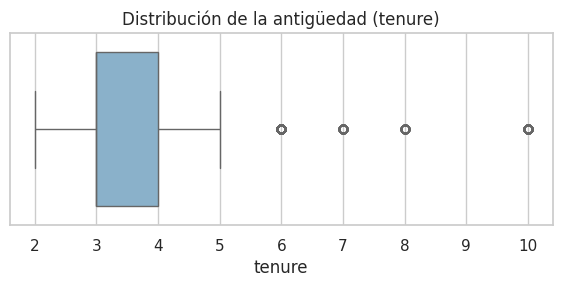

In [9]:
# Boxplot de la antigüedad para detectar outliers
plt.figure(figsize=(7, 2.5))
sns.boxplot(x=df1["tenure"], color="#7fb3d5")
plt.title("Distribución de la antigüedad (tenure)")
guardar("01_boxplot_tenure")
plt.show()

# Outliers con el método del rango intercuartílico (IQR)
q1, q3 = df1["tenure"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr
limite_inf = q1 - 1.5 * iqr
outliers_tenure = df1[(df1["tenure"] > limite_sup) | (df1["tenure"] < limite_inf)]
print(f"Límite inferior: {limite_inf}  |  Límite superior: {limite_sup}")
print(f"Empleados con antigüedad atípica: {len(outliers_tenure)}")


### Balance de la variable objetivo
Se fue el **16.6 %** de los empleados (1,991 de 11,991). Hay desbalance moderado, pero no tan extremo como para requerir técnicas de remuestreo. Uso muestreo estratificado y evalúo con AUC, precisión, recall y F1, no solo accuracy.

In [10]:
# Cuántos empleados se fueron vs. se quedaron
print(df1["left"].value_counts())
print()
print(df1["left"].value_counts(normalize=True).round(3))


left
0    10000
1     1991
Name: count, dtype: int64

left
0    0.834
1    0.166
Name: proportion, dtype: float64


### Visualizaciones

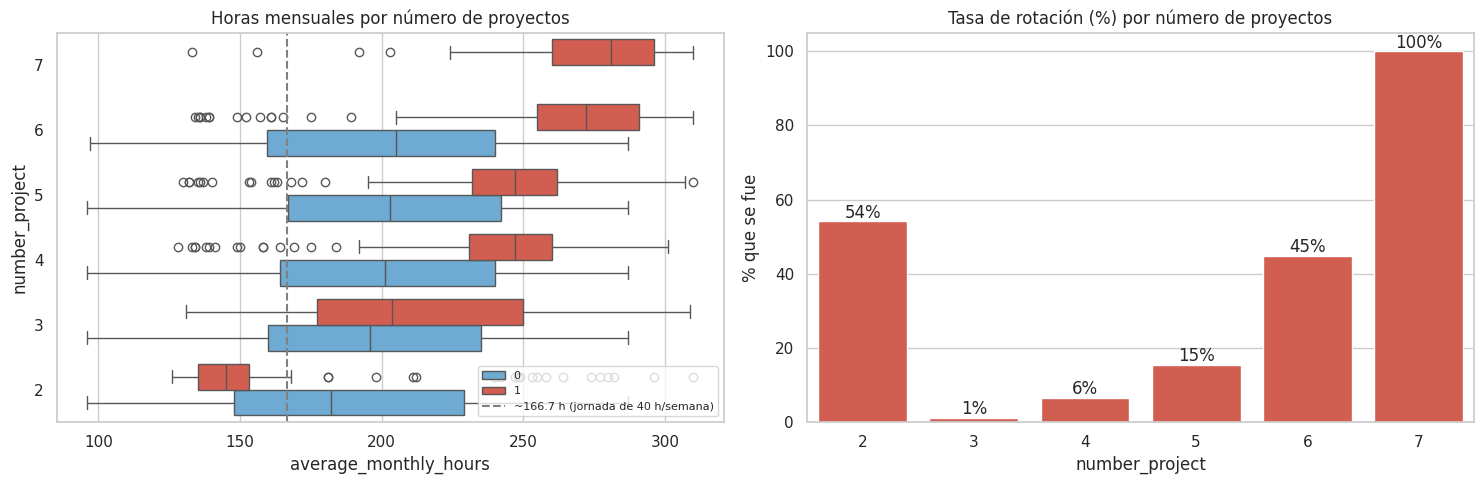

In [11]:
# Horas mensuales por número de proyectos, separado por rotación
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df1, x="average_monthly_hours", y="number_project",
            hue="left", orient="h", ax=ax[0], palette=["#5dade2", "#e74c3c"])
ax[0].invert_yaxis()
ax[0].set_title("Horas mensuales por número de proyectos")
ax[0].axvline(x=166.7, color="gray", ls="--", label="~166.7 h (jornada de 40 h/semana)")
ax[0].legend(loc="lower right", fontsize=8)

tasa = df1.groupby("number_project")["left"].mean().mul(100)
sns.barplot(x=tasa.index, y=tasa.values, ax=ax[1], color="#e74c3c")
ax[1].set_title("Tasa de rotación (%) por número de proyectos")
ax[1].set_ylabel("% que se fue")
for i, v in enumerate(tasa.values):
    ax[1].text(i, v + 1, f"{v:.0f}%", ha="center")
plt.tight_layout()
guardar("02_proyectos_horas_rotacion")
plt.show()


**Hallazgo 1: carga de trabajo.** Hay dos grupos de empleados que se van:
- Quienes tienen **solo 2 proyectos** y trabajan **menos** de lo esperado (¿desvinculados o poco involucrados?). Rotación del 54 %.
- Quienes tienen **6–7 proyectos** y trabajan **muchísimas horas** (sobrecarga). Con 6 proyectos se va el 45 %, y **con 7 proyectos se fueron el 100 %**.

El punto óptimo parece estar en **3–4 proyectos** (rotación de 1 % a 6 %).
Una jornada normal de 40 h/semana equivale a ~167 h/mes: casi todos los que tienen 3 o más proyectos trabajan **por encima** de eso.

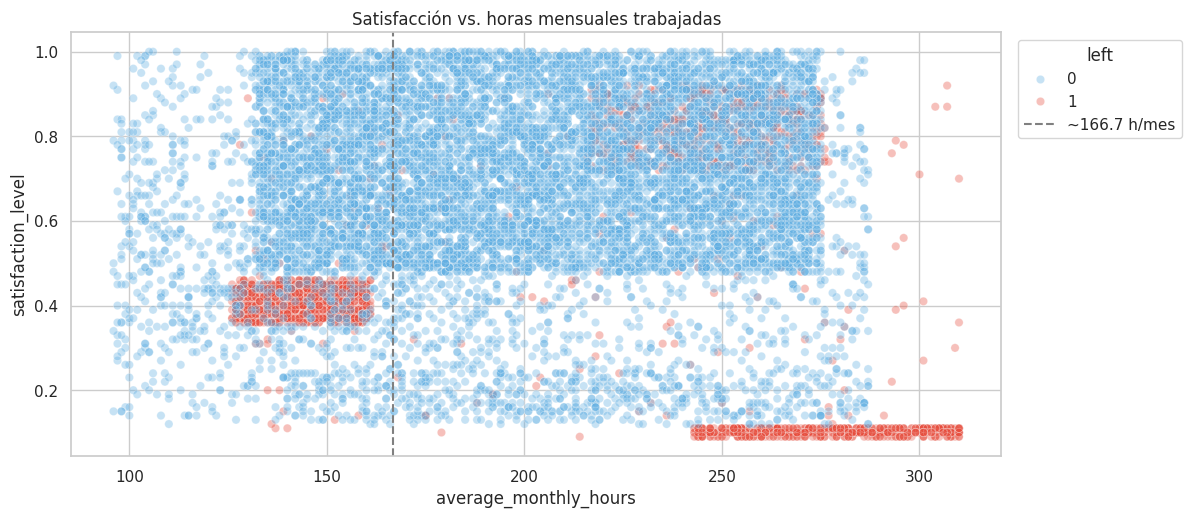

In [12]:
# Satisfacción vs. horas mensuales
plt.figure(figsize=(12, 5.5))
sns.scatterplot(data=df1, x="average_monthly_hours", y="satisfaction_level",
                hue="left", alpha=0.35, palette=["#5dade2", "#e74c3c"])
plt.axvline(x=166.7, color="gray", ls="--", label="~166.7 h/mes")
plt.title("Satisfacción vs. horas mensuales trabajadas")
plt.legend(title="left", loc="upper left", bbox_to_anchor=(1.01, 1))
guardar("03_satisfaccion_vs_horas")
plt.show()


**Hallazgo 2: satisfacción y horas.** Se distinguen grupos claros entre quienes se van:
1. Trabajan **~240–315 h/mes** y su satisfacción es **casi nula (~0.1)**: están quemados.
2. Trabajan una jornada normal (~130–160 h) y su satisfacción es **media-baja (~0.4)**.
3. Trabajan **~210–280 h** con satisfacción **alta (0.7–0.9)** pero se van igual: probablemente reciben mejores ofertas externas.

La forma "artificial" de estos grupos sugiere que el dataset puede tener datos sintéticos. Lo tomo en cuenta como limitación.

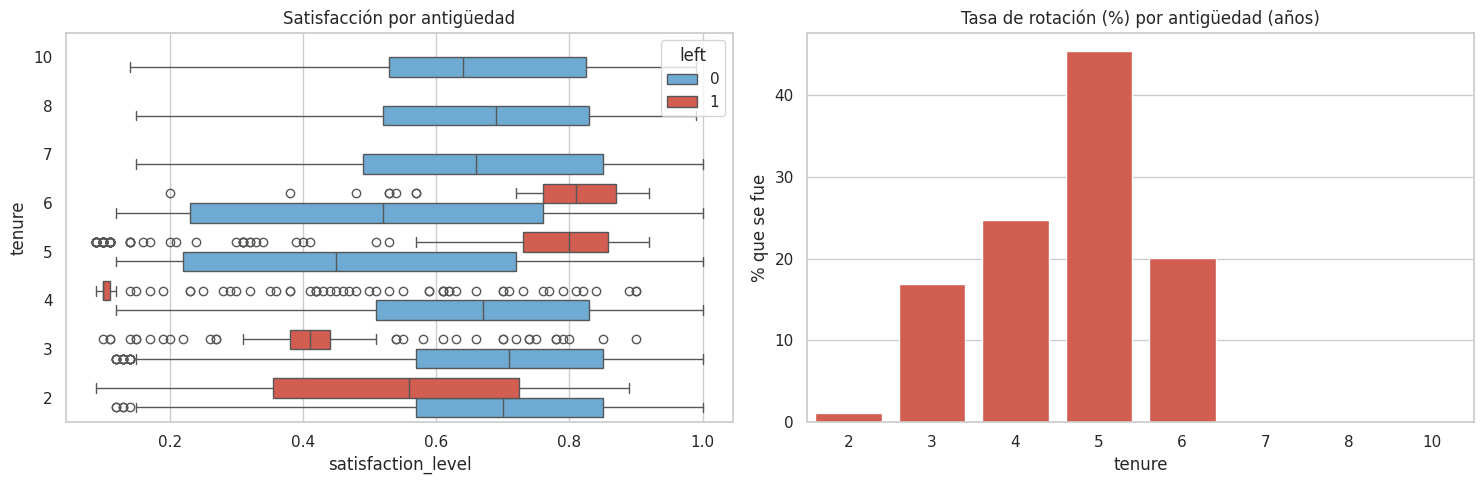

In [13]:
# Satisfacción y rotación según antigüedad
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df1, x="satisfaction_level", y="tenure", hue="left",
            orient="h", ax=ax[0], palette=["#5dade2", "#e74c3c"])
ax[0].invert_yaxis()
ax[0].set_title("Satisfacción por antigüedad")

tasa_t = df1.groupby("tenure")["left"].mean().mul(100)
sns.barplot(x=tasa_t.index, y=tasa_t.values, ax=ax[1], color="#e74c3c")
ax[1].set_title("Tasa de rotación (%) por antigüedad (años)")
ax[1].set_ylabel("% que se fue")
plt.tight_layout()
guardar("04_antiguedad")
plt.show()


**Hallazgo 3: antigüedad.** La rotación casi no existe en el año 2 (1 %) y se **dispara a los 5 años (45 %)**. Los empleados que se van a los 4 años tienen satisfacción **muy baja (~0.14 en promedio vs. 0.64 de quienes se quedan)**. Después de 6 años la rotación baja drásticamente (los que llegan a 7+ años no se van): probablemente son perfiles de mayor rango y sueldo.

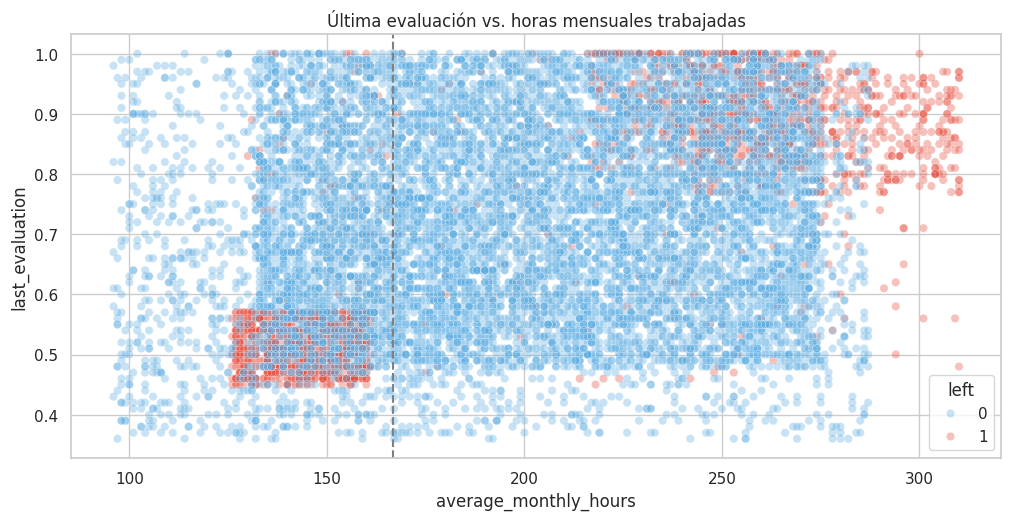

In [14]:
# Evaluación de desempeño vs. horas mensuales
plt.figure(figsize=(12, 5.5))
sns.scatterplot(data=df1, x="average_monthly_hours", y="last_evaluation",
                hue="left", alpha=0.35, palette=["#5dade2", "#e74c3c"])
plt.axvline(x=166.7, color="gray", ls="--")
plt.title("Última evaluación vs. horas mensuales trabajadas")
guardar("05_evaluacion_vs_horas")
plt.show()


**Hallazgo 4: desempeño.** Los empleados con **evaluación alta (>0.8) y más de 240 h/mes** tienen una rotación del **47 %**: se está perdiendo a los que más trabajan y mejor rinden. Trabajar muchas horas no garantiza buena evaluación: hay muchos con 250+ h y evaluación media.

promotion_last_5years
0    11788
1      203
Name: count, dtype: int64


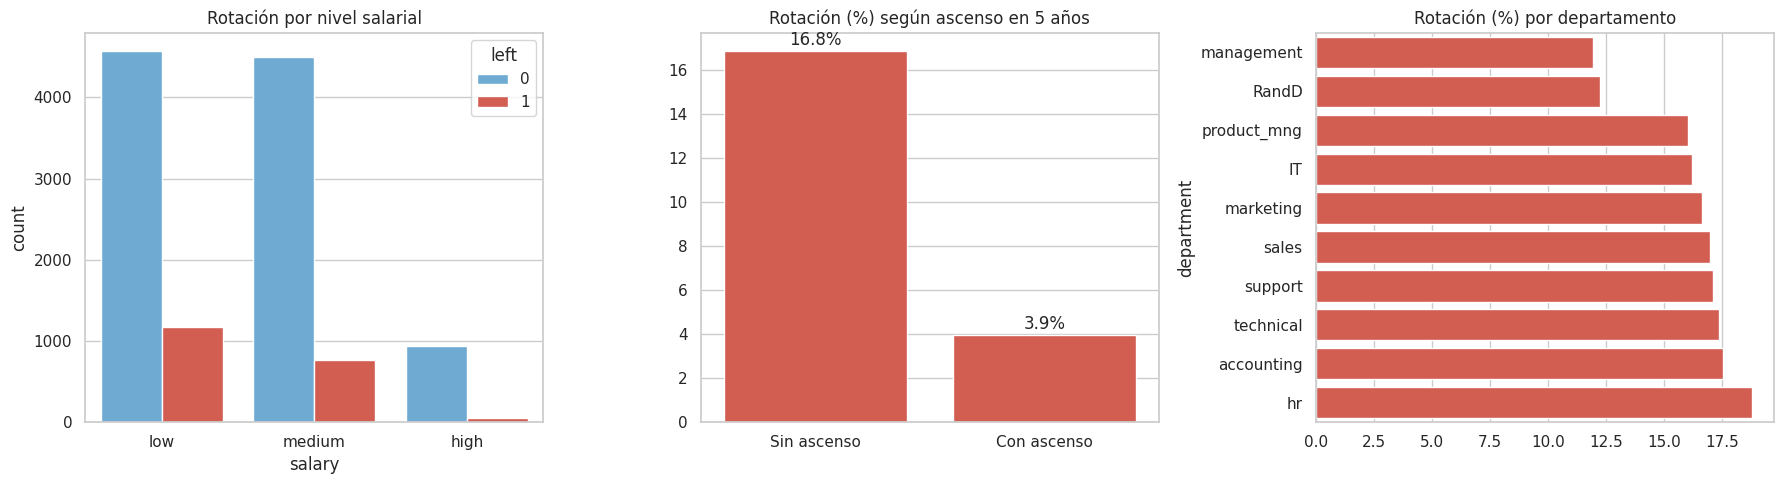

In [15]:
# Salario, ascensos y departamento
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df1, x="salary", hue="left", order=["low", "medium", "high"],
              ax=ax[0], palette=["#5dade2", "#e74c3c"])
ax[0].set_title("Rotación por nivel salarial")

prom = df1.groupby("promotion_last_5years")["left"].mean().mul(100)
sns.barplot(x=["Sin ascenso", "Con ascenso"], y=prom.values, ax=ax[1], color="#e74c3c")
ax[1].set_title("Rotación (%) según ascenso en 5 años")
for i, v in enumerate(prom.values):
    ax[1].text(i, v + 0.3, f"{v:.1f}%", ha="center")

dep = df1.groupby("department")["left"].mean().mul(100).sort_values()
sns.barplot(x=dep.values, y=dep.index, ax=ax[2], color="#e74c3c")
ax[2].set_title("Rotación (%) por departamento")
plt.tight_layout()
guardar("06_salario_ascenso_departamento")
plt.show()

print(df1["promotion_last_5years"].value_counts())


**Hallazgo 5: salario, ascensos y departamento.**
- **Salario:** rotación de 20.5 % (bajo), 14.6 % (medio) y 4.8 % (alto).
- **Ascensos:** solo 203 personas (1.7 %) fueron ascendidas en 5 años; de ellas se fue el 3.9 %, contra 16.8 % de quienes no.
- **Departamento:** la diferencia es pequeña (de 11.9 % en gerencia a 18.8 % en RR. HH.), así que **no es un factor determinante**.
- **Accidente laboral:** se van menos quienes tuvieron accidente (5.7 % vs. 18.6 %). Probablemente por antigüedad/arraigo, no por causalidad; lo trato con cautela.

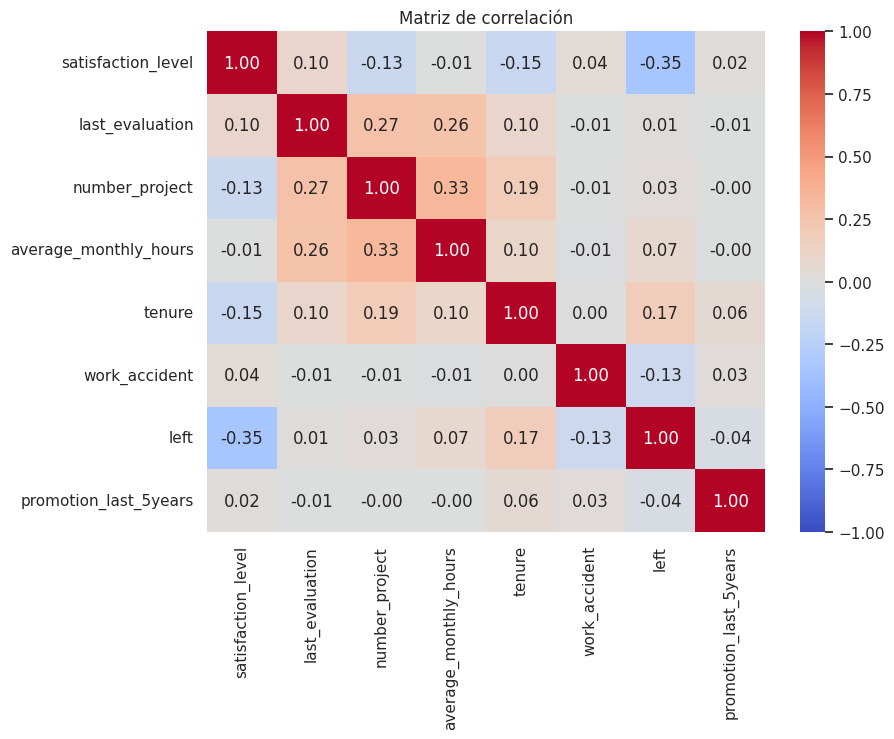

In [16]:
# Matriz de correlación
plt.figure(figsize=(9, 6.5))
corr = df1.select_dtypes("number").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriz de correlación")
guardar("07_correlacion")
plt.show()


La satisfacción es la variable más (negativamente) correlacionada con `left`. `number_project`, `average_monthly_hours` y `last_evaluation` están correlacionadas entre sí (más proyectos → más horas → mayor evaluación).

### Insights principales de la fase Analyze
- La rotación está dominada por **sobrecarga de trabajo** (6–7 proyectos, 240+ h/mes) y **bajo compromiso** (2 proyectos).
- Se concentra en la **ventana de 3–5 años de antigüedad**, con pico a los 5 años.
- La **satisfacción baja** acompaña a casi todas las salidas, pero **no toda la rotación es por insatisfacción** (525 de los 1,991 que se fueron tenían satisfacción > 0.7).
- **Salario bajo** y **falta de ascensos** aumentan la rotación; el departamento casi no influye.

# PACE: Construct
## Tipo de tarea de predicción
La variable objetivo `left` es **binaria** (se va / se queda), por lo tanto es un problema de **clasificación binaria**.

## Modelos elegidos
1. **Regresión logística:** modelo estadístico interpretable (odds ratios). Supone observaciones independientes, variable objetivo categórica, sin multicolinealidad severa ni outliers extremos, y relación lineal entre las predictoras y el logit.
2. **Árbol de decisión:** captura relaciones no lineales, no necesita escalar ni quitar outliers, es fácil de explicar.
3. **Random Forest:** conjunto de árboles; normalmente más preciso y estable que un solo árbol.

> Nota: usé estos tres modelos de scikit-learn. XGBoost era opcional en la actividad y decidí no incluirlo para mantener el proyecto reproducible solo con scikit-learn.

**Métricas** (la clase "se va" es la de interés): *AUC* (capacidad general de discriminar), *precisión* (de los que predigo que se van, cuántos realmente se van), *recall* (de los que realmente se van, cuántos detecto), *F1* (balance de ambas) y *accuracy*.

Como a RR. HH. le interesa **detectar** a quien se va, miro especialmente **recall, F1 y AUC**.

## Modelo 1: Regresión logística

Filas para regresión logística: 11167
              precision    recall  f1-score   support

    Se queda       0.86      0.93      0.90      2321
       Se va       0.44      0.26      0.33       471

    accuracy                           0.82      2792
   macro avg       0.65      0.60      0.61      2792
weighted avg       0.79      0.82      0.80      2792



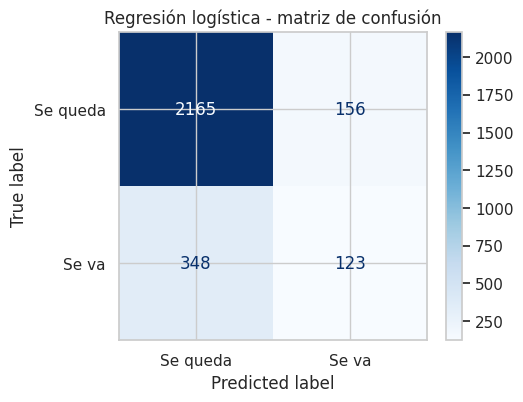

In [17]:
# --- MODELO 1: REGRESIÓN LOGÍSTICA ---
# Supuesto: sin outliers extremos -> se excluyen los outliers de antigüedad
df_lr = df1[(df1["tenure"] >= limite_inf) & (df1["tenure"] <= limite_sup)].copy()
print("Filas para regresión logística:", df_lr.shape[0])

# salary es ordinal -> se codifica 0/1/2 ; department es nominal -> variables dummy
df_lr["salary"] = df_lr["salary"].map({"low": 0, "medium": 1, "high": 2})
df_lr = pd.get_dummies(df_lr, drop_first=True, dtype=int)

X = df_lr.drop(columns="left")
y = df_lr["left"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

log_clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train, y_train)
y_pred_lr = log_clf.predict(X_test)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_lr),
                       display_labels=["Se queda", "Se va"]).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("Regresión logística - matriz de confusión")
guardar("08_cm_logistica")
plt.show()

print(classification_report(y_test, y_pred_lr, target_names=["Se queda", "Se va"]))


In [18]:
# Verificar multicolinealidad (supuesto de la regresión logística)
num = ["satisfaction_level", "last_evaluation", "number_project", "average_monthly_hours", "tenure"]
corr_num = X[num].corr().round(2)
print("Máxima correlación entre predictoras numéricas:",
      corr_num.where(~np.eye(len(num), dtype=bool)).abs().max().max().round(2))
corr_num


Máxima correlación entre predictoras numéricas: 0.34


                       satisfaction_level  ...  tenure
satisfaction_level                   1.00  ...   -0.22
last_evaluation                      0.10  ...    0.14
number_project                      -0.13  ...    0.26
average_monthly_hours               -0.01  ...    0.15
tenure                              -0.22  ...    1.00

[5 rows x 5 columns]

**Supuestos:** la variable objetivo es categórica; las observaciones se asumen independientes (una fila por empleado); la correlación máxima entre predictoras numéricas es 0.34, así que **no hay multicolinealidad severa**; los outliers de antigüedad fueron excluidos.

**Resultado:** accuracy de 82 % y AUC de 0.88, pero **recall de solo 26 %**: con el umbral estándar de 0.5 el modelo detecta apenas 1 de cada 4 personas que se van. Predice bien a quien se queda, y **no sirve como alerta temprana**. Se podría mejorar ajustando el umbral de decisión o aplicando `class_weight='balanced'`, pero los modelos de árboles resuelven mejor el problema (relaciones no lineales como "pocos O muchos proyectos").

In [19]:
# Coeficientes de la regresión logística (odds ratios) para interpretar el efecto
coef = pd.DataFrame({"variable": X_train.columns, "coeficiente": log_clf.coef_[0]})
coef["odds_ratio"] = np.exp(coef["coeficiente"])
coef = coef.reindex(coef["coeficiente"].abs().sort_values(ascending=False).index)
coef.head(8).round(3)


                variable  coeficiente  odds_ratio
0     satisfaction_level       -4.337       0.013
5          work_accident       -1.499       0.223
6  promotion_last_5years       -1.194       0.303
4                 tenure        1.099       3.001
7                 salary       -0.525       0.591
2         number_project       -0.482       0.618
8       department_RandD       -0.230       0.795
9  department_accounting       -0.198       0.820

Interpretación de los coeficientes (odds ratios): cada punto más de **satisfacción** reduce drásticamente las probabilidades de irse; cada **año adicional de antigüedad** las multiplica por ~3; haber sido **ascendido** o tener un **salario mayor** las reduce.

## Modelos 2 y 3: Árbol de decisión y Random Forest
Separo 75 % para entrenamiento y 25 % para prueba (estratificado), y ajusto hiperparámetros con **GridSearchCV** (validación cruzada de 4 pliegues, optimizando AUC).

In [20]:
# --- MODELOS BASADOS EN ÁRBOLES (Decision Tree y Random Forest) ---
# No requieren eliminar outliers ni escalar variables; se usa df1 completo
df_tree = df1.copy()
df_tree["salary"] = df_tree["salary"].map({"low": 0, "medium": 1, "high": 2})
df_tree = pd.get_dummies(df_tree, drop_first=False, dtype=int)

X = df_tree.drop(columns="left")
y = df_tree["left"]

# 75% entrenamiento / 25% prueba (test set intocable hasta el final)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)


Train: (8993, 18)  Test: (2998, 18)


In [21]:
def evaluar(nombre, modelo, X_t, y_t):
    """Devuelve las métricas de un modelo sobre el conjunto de prueba."""
    pred = modelo.predict(X_t)
    proba = modelo.predict_proba(X_t)[:, 1]
    return {"modelo": nombre,
            "precision": precision_score(y_t, pred),
            "recall": recall_score(y_t, pred),
            "f1": f1_score(y_t, pred),
            "accuracy": accuracy_score(y_t, pred),
            "auc": roc_auc_score(y_t, proba)}

scoring = {"accuracy": "accuracy", "precision": "precision",
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
resultados = []


### Ronda 1: con todas las variables

In [22]:
# Decision Tree - Ronda 1 (todas las variables)
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
grid_dt = {"max_depth": [4, 6, 8, None],
           "min_samples_leaf": [1, 2, 5],
           "min_samples_split": [2, 4, 6]}
dt1 = GridSearchCV(dt, grid_dt, scoring=scoring, cv=4, refit="roc_auc", n_jobs=-1).fit(X_train, y_train)

print("Mejores hiperparámetros:", dt1.best_params_)
print("AUC promedio en validación cruzada:", round(dt1.best_score_, 4))
resultados.append(evaluar("Decision Tree (ronda 1)", dt1.best_estimator_, X_test, y_test))
pd.DataFrame(resultados).round(3)


Mejores hiperparámetros: {'max_depth': 6, 'min_samples_leaf': 2, 'min_samples_split': 6}
AUC promedio en validación cruzada: 0.9759


                    modelo  precision  recall    f1  accuracy    auc
0  Decision Tree (ronda 1)      0.975   0.926  0.95     0.984  0.974

In [23]:
# Random Forest - Ronda 1 (todas las variables)
rf = RandomForestClassifier(random_state=RANDOM_STATE)
grid_rf = {"max_depth": [5, None],
           "max_samples": [0.7, 1.0],
           "min_samples_leaf": [1, 2, 3],
           "min_samples_split": [2, 4],
           "n_estimators": [200]}
rf1 = GridSearchCV(rf, grid_rf, scoring=scoring, cv=4, refit="roc_auc", n_jobs=-1).fit(X_train, y_train)

print("Mejores hiperparámetros:", rf1.best_params_)
print("AUC promedio en validación cruzada:", round(rf1.best_score_, 4))
resultados.append(evaluar("Random Forest (ronda 1)", rf1.best_estimator_, X_test, y_test))
pd.DataFrame(resultados).round(3)


Mejores hiperparámetros: {'max_depth': None, 'max_samples': 1.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
AUC promedio en validación cruzada: 0.9818


                    modelo  precision  recall     f1  accuracy    auc
0  Decision Tree (ronda 1)      0.975   0.926  0.950     0.984  0.974
1  Random Forest (ronda 1)      0.991   0.920  0.954     0.985  0.980

**Algo no cuadra:** los resultados son casi perfectos (AUC 0.97–0.98, recall >92 %). En un caso real eso es una **señal de alerta de fuga de datos (data leakage)**: `satisfaction_level` probablemente **no estaría disponible** para todos los empleados al momento de predecir, o ya refleja la decisión de irse. Además, las horas y proyectos pueden estar mezclados con la propia salida.

Para tener un modelo más realista y útil como herramienta preventiva hago una **segunda ronda**.

### Ronda 2: ingeniería de variables
Elimino `satisfaction_level` y reemplazo las horas mensuales por `overworked` (1 si trabaja más de 175 h/mes, ≈41 h/semana).

In [24]:
# --- INGENIERÍA DE VARIABLES (Ronda 2) ---
# Los modelos de la ronda 1 son casi perfectos: sospechoso (posible data leakage).
# satisfaction_level probablemente NO está disponible para todos los empleados en el
# momento de predecir (se mide en encuestas, y quien ya decidió irse responde distinto).
# Se elimina y se crea `overworked` (indicador de sobrecarga) en lugar de las horas.
df2 = df_tree.drop(columns="satisfaction_level").copy()
df2["overworked"] = (df2["average_monthly_hours"] > 175).astype(int)   # >175 h/mes ≈ >41 h/semana
df2 = df2.drop(columns="average_monthly_hours")

X2 = df2.drop(columns="left")
y2 = df2["left"]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.25, stratify=y2, random_state=RANDOM_STATE)
print("Variables ronda 2:", X2.columns.tolist())


Variables ronda 2: ['last_evaluation', 'number_project', 'tenure', 'work_accident', 'promotion_last_5years', 'salary', 'department_IT', 'department_RandD', 'department_accounting', 'department_hr', 'department_management', 'department_marketing', 'department_product_mng', 'department_sales', 'department_support', 'department_technical', 'overworked']


In [25]:
# Decision Tree - Ronda 2
dt2 = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), grid_dt,
                   scoring=scoring, cv=4, refit="roc_auc", n_jobs=-1).fit(X2_train, y2_train)
print("Mejores hiperparámetros:", dt2.best_params_)
resultados.append(evaluar("Decision Tree (ronda 2)", dt2.best_estimator_, X2_test, y2_test))


Mejores hiperparámetros: {'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 4}


In [26]:
# Random Forest - Ronda 2
rf2 = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), grid_rf,
                   scoring=scoring, cv=4, refit="roc_auc", n_jobs=-1).fit(X2_train, y2_train)
print("Mejores hiperparámetros:", rf2.best_params_)
resultados.append(evaluar("Random Forest (ronda 2)", rf2.best_estimator_, X2_test, y2_test))


Mejores hiperparámetros: {'max_depth': None, 'max_samples': 1.0, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 200}


## Resultados y comparación de modelos

In [27]:
# Agregar la regresión logística a la tabla comparativa (se evalúa en su propio test set)
Xl = df_lr.drop(columns="left"); yl = df_lr["left"]
_, Xl_test, _, yl_test = train_test_split(Xl, yl, test_size=0.25, stratify=yl, random_state=RANDOM_STATE)
resultados.insert(0, evaluar("Regresión Logística", log_clf, Xl_test, yl_test))

tabla = pd.DataFrame(resultados).set_index("modelo").round(3)
tabla


                         precision  recall     f1  accuracy    auc
modelo                                                            
Regresión Logística          0.441   0.261  0.328     0.819  0.883
Decision Tree (ronda 1)      0.975   0.926  0.950     0.984  0.974
Random Forest (ronda 1)      0.991   0.920  0.954     0.985  0.980
Decision Tree (ronda 2)      0.809   0.926  0.863     0.951  0.963
Random Forest (ronda 2)      0.913   0.890  0.901     0.968  0.966

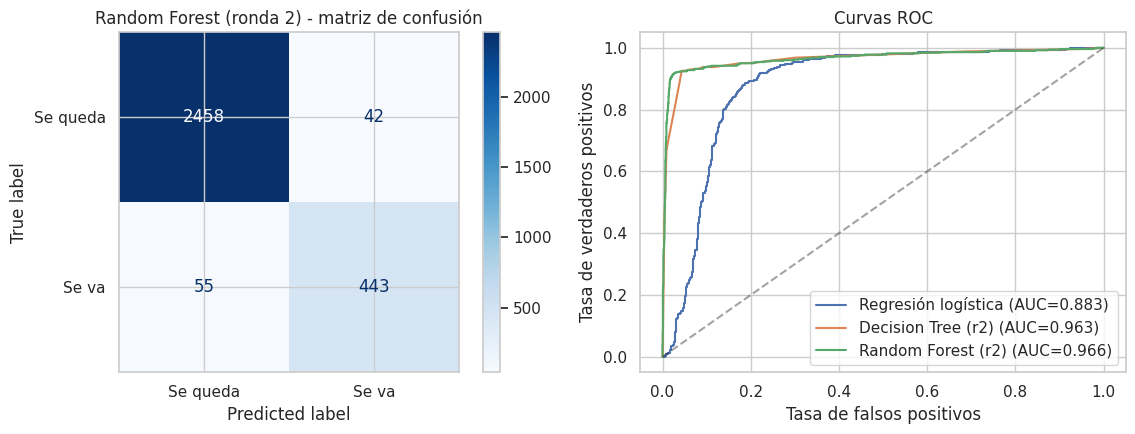

In [28]:
# Matriz de confusión del Random Forest ronda 2 y curva ROC comparativa
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
pred = rf2.best_estimator_.predict(X2_test)
ConfusionMatrixDisplay(confusion_matrix(y2_test, pred),
                       display_labels=["Se queda", "Se va"]).plot(ax=ax[0], cmap="Blues", values_format="d")
ax[0].set_title("Random Forest (ronda 2) - matriz de confusión")

for nombre, modelo, Xt, yt in [("Regresión logística", log_clf, Xl_test, yl_test),
                               ("Decision Tree (r2)", dt2.best_estimator_, X2_test, y2_test),
                               ("Random Forest (r2)", rf2.best_estimator_, X2_test, y2_test)]:
    fpr, tpr, _ = roc_curve(yt, modelo.predict_proba(Xt)[:, 1])
    ax[1].plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(yt, modelo.predict_proba(Xt)[:, 1]):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[1].set_xlabel("Tasa de falsos positivos"); ax[1].set_ylabel("Tasa de verdaderos positivos")
ax[1].set_title("Curvas ROC"); ax[1].legend(loc="lower right")
plt.tight_layout()
guardar("09_cm_roc_final")
plt.show()


**Lectura:** aun sin la satisfacción, el **Random Forest (ronda 2)** mantiene un desempeño muy alto (**AUC 0.966, precisión 0.91, recall 0.89, F1 0.90**), claramente superior a la regresión logística (recall 0.26). Es mi **modelo final**. El árbol de decisión es un poco menos preciso pero más fácil de explicar.

> Las métricas se calculan en el conjunto de prueba, que no se usó para entrenar ni para elegir hiperparámetros. La regresión logística se evalúa sobre su propio conjunto de prueba (sin outliers), por lo que la comparación es orientativa.

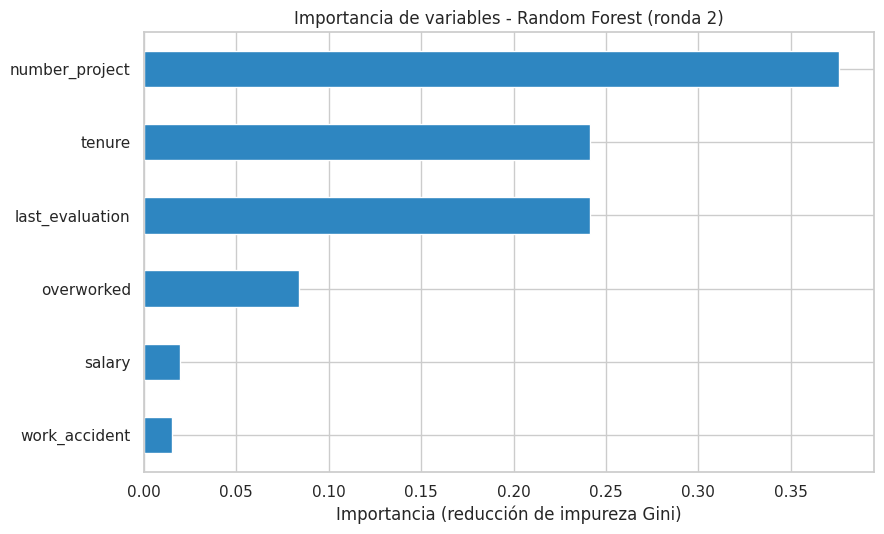

number_project     0.376
tenure             0.241
last_evaluation    0.241
overworked         0.084
salary             0.019
work_accident      0.015
dtype: float64

In [29]:
# Importancia de variables - Random Forest ronda 2
imp = pd.Series(rf2.best_estimator_.feature_importances_, index=X2.columns).sort_values()
imp = imp[imp > 0.005]   # mostrar solo las relevantes

plt.figure(figsize=(9, 5.5))
imp.plot(kind="barh", color="#2e86c1")
plt.title("Importancia de variables - Random Forest (ronda 2)")
plt.xlabel("Importancia (reducción de impureza Gini)")
plt.tight_layout()
guardar("10_importancia_variables")
plt.show()
imp.sort_values(ascending=False).round(3)


In [30]:
# Importancia de variables - Decision Tree ronda 2 (para comparar)
imp_dt = pd.Series(dt2.best_estimator_.feature_importances_, index=X2.columns)
imp_dt[imp_dt > 0.01].sort_values(ascending=False).round(3)


number_project     0.344
last_evaluation    0.335
tenure             0.214
overworked         0.104
dtype: float64

# PACE: Execute
## Variables más importantes
En ambos modelos de árboles dominan: **`number_project`**, **`last_evaluation`**, **`tenure`** y **`overworked`**. Es decir, la rotación se explica sobre todo por **carga de trabajo, desempeño y etapa de carrera**, no por departamento.

## Resumen de resultados
- **Modelo final:** Random Forest con AUC 0.966, precisión 91 %, recall 89 %, F1 0.90 y accuracy 96.8 % en datos no vistos.
- La regresión logística queda como referencia interpretable, pero no detecta bien a quienes se van.
- Los resultados de la ronda 1 (AUC 0.98) se descartan como engañosos por posible fuga de datos.

## Conclusiones y recomendaciones para la dirección
1. **Topar el número de proyectos por persona.** Con 6–7 proyectos la rotación llega a 45–100 %; el rango sano es 3–4. Definir un máximo (p. ej. 5).
2. **Reconocer o compensar las horas extra**, o dejar de esperarlas. El 64 % del personal trabaja más de 175 h/mes.
3. **Revisar el año 3 al 5 de carrera.** Ahí está el pico de salidas. Planes de desarrollo, ascensos claros y conversaciones de carrera antes del año 4.
4. **Política de ascensos:** solo 1.7 % fue ascendido en 5 años y esas personas rara vez se van (3.9 %).
5. **Retener al talento de alto desempeño:** quienes tienen evaluación alta y 240+ h/mes se van en 47 %. Revisar su carga y compensación.
6. **Atender a quienes tienen poca carga (2 proyectos):** aclarar expectativas, reasignar trabajo o replantear el puesto.
7. **Cultura de trabajo:** si trabajar más de 60 h por semana es lo esperado, hay que hacerlo explícito o corregirlo. Mejorar la satisfacción general.

## Siguientes pasos
- Usar el modelo como **sistema de alerta temprana** (no para sancionar) combinado con entrevistas de salida.
- **Recolectar más datos:** motivo real de salida (renuncia vs. despido), edad, jefe directo, clima laboral, ofertas externas, tiempo desde el último aumento.
- Validar con datos reales de Salifort: el dataset parece tener patrones sintéticos.
- Probar **XGBoost**, ajustar el umbral de decisión y estimar el **costo de la rotación** para priorizar acciones por retorno.
- Medir si las intervenciones (menos proyectos, ascensos) reducen la rotación (prueba piloto).

## Limitaciones
Datos de una encuesta (posible sesgo), 20 % de filas duplicadas eliminadas, correlación ≠ causalidad, y no se distingue entre renuncia y despido.